# Práctica 2 · Ejercicio 2: alineamiento «todos contra todos» del citocromo c

**Enunciado.** Cargar un FASTA con 5 secuencias de la misma proteína (humano, chimpancé,
ratón, pez y mosca) con `Bio.SeqIO`, calcular el `.score` del alineamiento global con
BLOSUM62 para cada par de especies, guardar las 25 puntuaciones en una matriz, dibujarla
como *heatmap*, probar otras matrices de sustitución y comentar los resultados.

**Proteína elegida: citocromo c.** Es una proteína pequeña (~105 aa) de la cadena
respiratoria mitocondrial que está en prácticamente todos los eucariotas. Es el ejemplo
clásico de reloj molecular (Margoliash, 1963): cambia muy despacio, pero lo suficiente como
para distinguir especies, así que encaja muy bien con este ejercicio.

| Especie | Nombre científico | UniProt |
|---|---|---|
| Humano | *Homo sapiens* | [P99999](https://www.uniprot.org/uniprotkb/P99999) |
| Chimpancé | *Pan troglodytes* | [P99998](https://www.uniprot.org/uniprotkb/P99998) |
| Ratón | *Mus musculus* | [P62897](https://www.uniprot.org/uniprotkb/P62897) |
| Pez cebra | *Danio rerio* | [Q6IQM2](https://www.uniprot.org/uniprotkb/Q6IQM2) |
| Mosca | *Drosophila melanogaster* (Cyt-c-p) | [P84029](https://www.uniprot.org/uniprotkb/P84029) |

El FASTA está en `data/citocromo_c.fasta`; se generó con `descargar_secuencias.py`.

**Índice**
1. Carga de las secuencias
2. Alineamiento todos contra todos con BLOSUM62
3. Heatmap de las puntuaciones
4. Puntuación normalizada e identidad *(aportación)*
5. Un vistazo a un alineamiento: humano frente a mosca *(aportación)*
6. Otras matrices de sustitución
7. Árbol a partir de las puntuaciones *(aportación)*
8. Efecto de los huecos en los extremos *(aportación)*
9. Conclusiones

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

DATOS = Path("data")
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)

sns.set_theme(style="white", context="notebook")
plt.rcParams["figure.dpi"] = 110

## 1. Carga de las secuencias

`SeqIO.parse` devuelve un `SeqRecord` por cada entrada del FASTA. El ID de cada registro es
el nombre de la especie, que usaremos como etiqueta en las tablas y gráficos.

In [2]:
registros = list(SeqIO.parse(DATOS / "citocromo_c.fasta", "fasta"))
especies = [r.id for r in registros]

pd.DataFrame(
    {
        "Especie": especies,
        "Organismo": [r.description.split("OS=")[1].split(" OX=")[0] for r in registros],
        "Longitud (aa)": [len(r.seq) for r in registros],
        "Inicio de la secuencia": [str(r.seq[:30]) + "…" for r in registros],
    }
)

,Especie,Organismo,Longitud (aa),Inicio de la secuencia
0,Humano,Homo sapiens,105,MGDVEKGKKIFIMKCSQCHTVEKGGKHKTG…
1,Chimpance,Pan troglodytes,105,MGDVEKGKKIFIMKCSQCHTVEKGGKHKTG…
2,Raton,Mus musculus,105,MGDVEKGKKIFVQKCAQCHTVEKGGKHKTG…
3,Pez_cebra,Danio rerio,104,MGDVEKGKKVFVQKCAQCHTVENGGKHKVG…
4,Mosca,Drosophila melanogaster,108,MGVPAGDVEKGKKLFVQRCAQCHTVEAGGK…


Las longitudes son casi iguales (104-108 aa). La mosca tiene 3 residuos más en el extremo
N-terminal y al pez le falta el último. A simple vista, las secuencias de humano y
chimpancé son idénticas.

## 2. Alineamiento todos contra todos con BLOSUM62

Configuramos un `PairwiseAligner` en modo **global** (Needleman-Wunsch) con la matriz
**BLOSUM62** y las penalizaciones de hueco por defecto de EMBOSS `needle`: **-10 para abrir**
un hueco y **-0.5 para extenderlo**. Para la puntuación usamos `aligner.score()`, que
calcula el valor óptimo sin construir los alineamientos, así que es más rápido que
`align()`.

El bucle recorre las 5 × 5 = 25 combinaciones, incluida la diagonal (cada especie contra sí
misma) y los dos sentidos de cada par. Así comprobamos que la puntuación es simétrica.

In [3]:
def crear_alineador(matriz="BLOSUM62", abrir=-10, extender=-0.5):
    alineador = Align.PairwiseAligner()
    alineador.mode = "global"
    alineador.substitution_matrix = substitution_matrices.load(matriz)
    alineador.open_gap_score = abrir
    alineador.extend_gap_score = extender
    return alineador


def matriz_puntuaciones(registros, alineador):
    # Bucle de todos contra todos: 25 alineamientos para 5 secuencias
    n = len(registros)
    puntuaciones = np.zeros((n, n))
    for i, a in enumerate(registros):
        for j, b in enumerate(registros):
            puntuaciones[i, j] = alineador.score(a.seq, b.seq)
    etiquetas = [r.id for r in registros]
    return pd.DataFrame(puntuaciones, index=etiquetas, columns=etiquetas)


alineador = crear_alineador("BLOSUM62")

scores_b62 = matriz_puntuaciones(registros, alineador)
assert np.allclose(scores_b62.values, scores_b62.values.T), "La matriz debería ser simétrica"
scores_b62.to_csv(RESULTADOS / "scores_blosum62.csv")
scores_b62

,Humano,Chimpance,Raton,Pez_cebra,Mosca
Humano,565.0,565.0,522.0,475.0,431.5
Chimpance,565.0,565.0,522.0,475.0,431.5
Raton,522.0,522.0,565.0,504.0,466.5
Pez_cebra,475.0,475.0,504.0,558.0,464.5
Mosca,431.5,431.5,466.5,464.5,578.0


## 3. Heatmap de las puntuaciones

Usamos una escala secuencial: cuanto más claro el color, mayor es la puntuación.

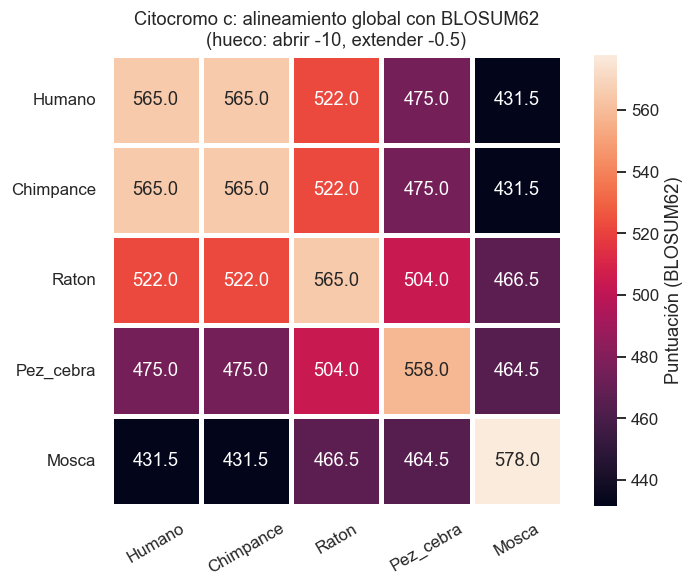

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    scores_b62, annot=True, fmt=".1f", cmap="rocket", square=True,
    linewidths=2, linecolor="white", cbar_kws={"label": "Puntuación (BLOSUM62)"}, ax=ax,
)
ax.set_title("Citocromo c: alineamiento global con BLOSUM62\n(hueco: abrir -10, extender -0.5)")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(RESULTADOS / "heatmap_blosum62.png", bbox_inches="tight")
plt.show()

**Qué se ve**

- **Diagonal.** Es la puntuación de cada secuencia contra sí misma, la máxima posible para
  esa secuencia. No es igual para todas: la de la mosca (578) es la más alta porque su
  secuencia es la más larga y BLOSUM62 da más puntos a unos aminoácidos idénticos que a
  otros (W-W vale 11, A-A solo 4).
- **Humano = chimpancé.** Su puntuación cruzada (565) es igual que la de cada uno contra sí
  mismo: el citocromo c de las dos especies es **idéntico, residuo a residuo**. Sus filas
  del heatmap son iguales.
- **La puntuación baja con la distancia evolutiva.** En la fila del humano se ve
  chimpancé (565) > ratón (522) > pez (475) > mosca (431.5), el mismo orden en que esos
  linajes se separaron del nuestro (unos 6, 90, 430 y 600 millones de años).
- **Algo inesperado.** El ratón se parece más al pez (504) y a la mosca (466.5) que el
  humano (475 y 431.5). Es un resultado conocido: **el citocromo c evolucionó más deprisa en
  los primates antropoides** (Grossman et al., 2001), así que nuestra versión se ha alejado
  más de la ancestral que la del ratón. El «reloj molecular» no va al mismo ritmo en todos
  los linajes.
- **Ninguna puntuación es baja.** Incluso humano y mosca, separados por unos 600 millones
  de años, tienen 81 de 105 residuos idénticos. Es una proteína muy conservada.

La puntuación bruta tiene un problema: depende de la longitud y de la composición de las
secuencias, así que no sirve para comparar pares de secuencias distintas. Lo corregimos en
la sección siguiente.

## 4. Puntuación normalizada e identidad *(aportación)*

Para comparar pares entre sí dividimos cada puntuación por la media geométrica de las
dos autopuntuaciones:

$$S_{norm}(a,b) = \frac{S(a,b)}{\sqrt{S(a,a)\,S(b,b)}}$$

Vale 1 si las secuencias son idénticas y es una medida parecida a una correlación. También
calculamos el **porcentaje de identidad**, que es la medida más fácil de interpretar:
residuos idénticos ÷ longitud del alineamiento.

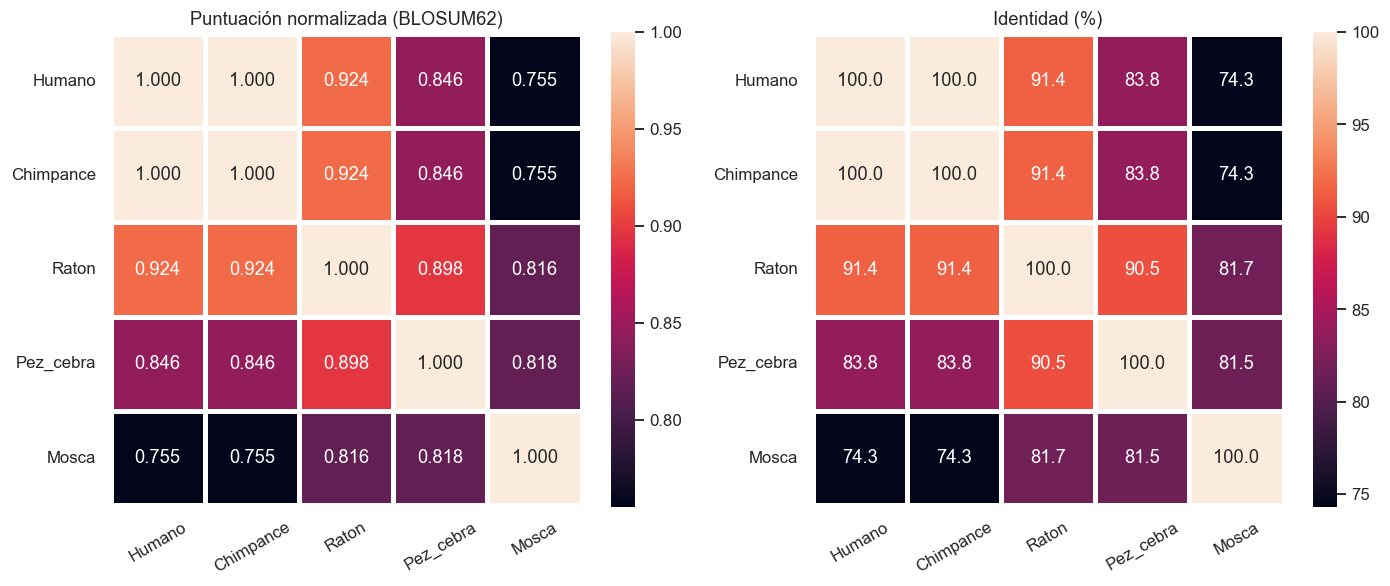

In [5]:
def normalizar(scores):
    diagonal = np.diag(scores.values)
    return scores / np.sqrt(np.outer(diagonal, diagonal))


def identidad(a, b, alineador):
    aln = alineador.align(a.seq, b.seq)[0]
    return 100 * aln.counts().identities / aln.length


norm_b62 = normalizar(scores_b62)
ident = pd.DataFrame(
    [[identidad(a, b, alineador) for b in registros] for a in registros],
    index=especies, columns=especies,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, datos, titulo, fmt in [
    (axes[0], norm_b62, "Puntuación normalizada (BLOSUM62)", ".3f"),
    (axes[1], ident, "Identidad (%)", ".1f"),
]:
    sns.heatmap(datos, annot=True, fmt=fmt, cmap="rocket", square=True,
                linewidths=2, linecolor="white", ax=ax)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(RESULTADOS / "heatmap_normalizado_identidad.png", bbox_inches="tight")
plt.show()

Con la normalización la diagonal vale 1 en todas las especies y los valores fuera de ella
se pueden comparar. Las dos medidas cuentan lo mismo, pero se lee mejor:

- Humano–ratón: **91 % de identidad** (9 diferencias).
- Humano–pez: **~84 %**. Humano–mosca: **~74 %**.
- Ratón–pez (≈90 %) está casi al nivel de humano–ratón, lo que confirma la aceleración en
  primates del apartado anterior.

La identidad y la puntuación normalizada ordenan los pares casi igual, pero no exactamente:
BLOSUM62 da puntos parciales a las sustituciones «conservadoras» (por ejemplo K→R o I→V),
que la identidad cuenta como fallos.

## 5. Un vistazo a un alineamiento: humano frente a mosca *(aportación)*

Las puntuaciones resumen el alineamiento en un número. Veamos el par más distante y
comprobemos si los residuos funcionales del citocromo c se conservan:

- **Motivo CXXCH** (Cys14, Cys17, His18 en la numeración de la proteína madura): fija el
  grupo hemo a la proteína mediante dos enlaces tioéter.
- **Met80**: es el sexto ligando del hierro del hemo.

La numeración clásica empieza tras la metionina inicial, que se elimina en la proteína
madura. Por eso en nuestras secuencias (que la incluyen) esas posiciones van desplazadas
una unidad.

In [6]:
humano, mosca = registros[0], registros[-1]
aln = alineador.align(humano.seq, mosca.seq)[0]
print(f"Puntuación: {aln.score}   Alineamientos óptimos empatados: {len(alineador.align(humano.seq, mosca.seq))}\n")
print(aln)

# Residuos clave en la numeración de la proteína madura (sin la Met inicial)
residuos_clave = {"Cys14": 14, "Cys17": 17, "His18": 18, "Met80": 80}

# Mapa posición en humano -> posición alineada en mosca
mapa = {}
for (h0, h1), (m0, m1) in zip(*aln.aligned):
    for k in range(h1 - h0):
        mapa[h0 + k] = m0 + k

print("Residuos funcionales:")
for nombre, pos in residuos_clave.items():
    i = pos  # índice 0 en la secuencia con Met inicial
    j = mapa.get(i)
    res_m = mosca.seq[j] if j is not None else "-"
    marca = "conservado" if res_m == humano.seq[i] else "CAMBIA"
    print(f"  {nombre:<6} humano={humano.seq[i]}  mosca={res_m}  -> {marca}")

Puntuación: 431.5   Alineamientos óptimos empatados: 2

target            0 M----GDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNK
                  0 |----||||||||.|...|.||||||.|||||.|||||||.|||||||.|..||.|||.|
query             0 MGVPAGDVEKGKKLFVQRCAQCHTVEAGGKHKVGPNLHGLIGRKTGQAAGFAYTDANKAK

target           56 GIIWGEDTLMEYLENPKKYIPGTKMIFVGIKKKEERADLIAYLKKATNE 105
                 60 ||.|.||||.|||||||||||||||||.|.||..||.|||||||.||-. 109
query            60 GITWNEDTLFEYLENPKKYIPGTKMIFAGLKKPNERGDLIAYLKSAT-K 108

Residuos funcionales:
  Cys14  humano=C  mosca=C  -> conservado
  Cys17  humano=C  mosca=C  -> conservado
  His18  humano=H  mosca=H  -> conservado
  Met80  humano=M  mosca=M  -> conservado


Los cuatro residuos que sujetan el hemo son los mismos en humano y mosca. Además, hay **2
alineamientos óptimos empatados** con la misma puntuación (el hueco interno puede ir en
dos sitios equivalentes); `.score` es el mismo, pero solo mostramos el primero. Las
diferencias están en la superficie de la proteína, donde no afectan a su función. Además, el
alineamiento global coloca un hueco de 4 residuos al principio para absorber la extensión
N-terminal de la mosca. Volveremos sobre esto en la sección 8.

## 6. Otras matrices de sustitución

Repetimos el mismo bucle con otras matrices de dos familias:

- **BLOSUM-n** (Henikoff y Henikoff, 1992): se calculan a partir de bloques de secuencias
  que comparten como máximo un n % de identidad. **Un número alto significa una matriz para
  secuencias cercanas** (BLOSUM80, BLOSUM90) y un número bajo, para secuencias lejanas
  (BLOSUM45).
- **PAM-n** (Dayhoff, 1978): se extrapolan de alineamientos de secuencias muy parecidas.
  **Un número alto significa más distancia evolutiva** (PAM250 para secuencias lejanas,
  PAM30 para cercanas). La escala va al revés que en BLOSUM.

In [7]:
matrices = ["BLOSUM45", "BLOSUM62", "BLOSUM80", "BLOSUM90", "PAM30", "PAM70", "PAM250"]

scores = {m: matriz_puntuaciones(registros, crear_alineador(m)) for m in matrices}

# Tabla resumen: los 10 pares distintos (triángulo superior) con cada matriz
pares = list(combinations(especies, 2))
tabla_pares = pd.DataFrame(
    {m: [scores[m].loc[a, b] for a, b in pares] for m in matrices},
    index=[f"{a}–{b}" for a, b in pares],
)
tabla_pares.to_csv(RESULTADOS / "scores_por_matriz.csv")
tabla_pares

,BLOSUM45,BLOSUM62,BLOSUM80,BLOSUM90,PAM30,PAM70,PAM250
Humano–Chimpance,657.0,565.0,908.0,657.0,801.0,696.0,538.0
Humano–Raton,605.0,522.0,831.0,601.0,716.0,635.0,506.0
Humano–Pez_cebra,553.0,475.0,758.0,541.0,632.0,572.0,470.0
Humano–Mosca,507.5,431.5,691.5,486.5,545.5,508.5,429.5
Chimpance–Raton,605.0,522.0,831.0,601.0,716.0,635.0,506.0
Chimpance–Pez_cebra,553.0,475.0,758.0,541.0,632.0,572.0,470.0
Chimpance–Mosca,507.5,431.5,691.5,486.5,545.5,508.5,429.5
Raton–Pez_cebra,589.0,504.0,812.0,580.0,689.0,611.0,486.0
Raton–Mosca,550.5,466.5,754.5,532.5,610.5,552.5,446.5
Pez_cebra–Mosca,545.5,464.5,746.5,530.5,609.5,552.5,449.5


Las puntuaciones brutas cambian mucho de una matriz a otra (humano–humano vale 565 con
BLOSUM62 y 908 con BLOSUM80), porque **cada matriz usa su propia escala**. Para compararlas
hay que normalizarlas. A continuación dibujamos las siete normalizadas con la misma escala
de color:

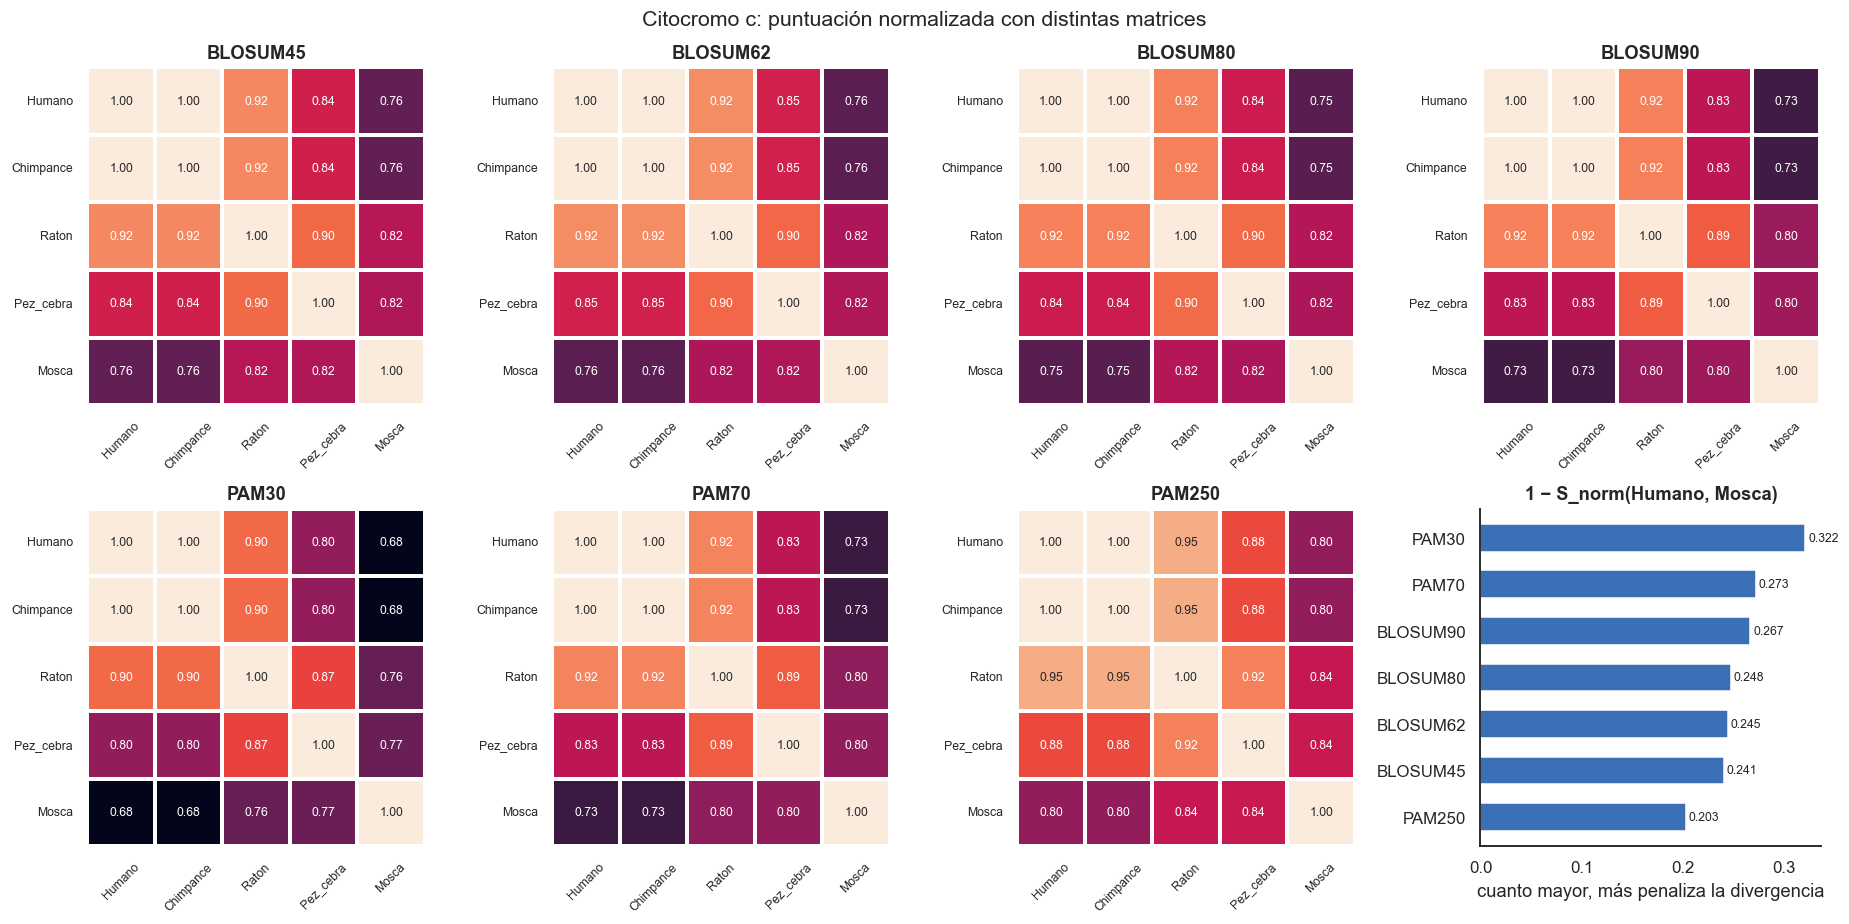

In [8]:
normalizadas = {m: normalizar(s) for m, s in scores.items()}
vmin = min(n.values.min() for n in normalizadas.values())

fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, m in zip(axes.flat, matrices):
    sns.heatmap(normalizadas[m], annot=True, fmt=".2f", cmap="rocket", vmin=vmin, vmax=1,
                square=True, linewidths=1.5, linecolor="white", cbar=False, ax=ax,
                annot_kws={"size": 8})
    ax.set_title(m, fontweight="bold")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

# El último hueco de la rejilla muestra cuánto "separa" cada matriz al humano de la mosca
ax = axes.flat[-1]
separacion = pd.Series({m: 1 - normalizadas[m].loc["Humano", "Mosca"] for m in matrices}).sort_values()
ax.barh(separacion.index, separacion.values, color="#3b6fb6", height=0.6)
ax.set_title("1 − S_norm(Humano, Mosca)", fontweight="bold")
ax.set_xlabel("cuanto mayor, más penaliza la divergencia")
for y, v in enumerate(separacion.values):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Citocromo c: puntuación normalizada con distintas matrices", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTADOS / "heatmaps_matrices.png", bbox_inches="tight")
plt.show()

¿Cambia el **orden** de los pares de más a menos parecido según la matriz? Para comprobarlo
calculamos la correlación de Spearman (por rangos) entre las puntuaciones normalizadas de
los 10 pares:

Ranking de pares (1 = más parecidos) según cada matriz:


,BLOSUM45,BLOSUM62,BLOSUM80,BLOSUM90,PAM30,PAM70,PAM250
Humano–Chimpance,1,1,1,1,1,1,1
Humano–Raton,2,2,2,2,2,2,2
Humano–Pez_cebra,5,5,5,5,5,5,5
Humano–Mosca,9,9,9,9,9,9,9
Chimpance–Raton,2,2,2,2,2,2,2
Chimpance–Pez_cebra,5,5,5,5,5,5,5
Chimpance–Mosca,9,9,9,9,9,9,9
Raton–Pez_cebra,4,4,4,4,4,4,4
Raton–Mosca,7,8,7,8,8,8,8
Pez_cebra–Mosca,8,7,8,7,7,7,7


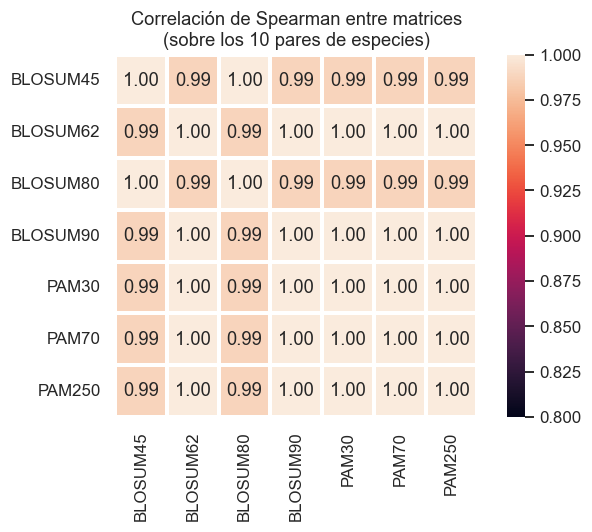

In [9]:
tabla_norm = pd.DataFrame(
    {m: [normalizadas[m].loc[a, b] for a, b in pares] for m in matrices},
    index=[f"{a}–{b}" for a, b in pares],
)

print("Ranking de pares (1 = más parecidos) según cada matriz:")
display(tabla_norm.rank(ascending=False, method="min").astype(int))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(tabla_norm.corr(method="spearman"), annot=True, fmt=".2f", cmap="rocket",
            vmin=0.8, vmax=1, square=True, linewidths=1.5, linecolor="white", ax=ax)
ax.set_title("Correlación de Spearman entre matrices\n(sobre los 10 pares de especies)")
fig.tight_layout()
plt.show()

**Comentario sobre las matrices**

- **El orden apenas cambia.** Las correlaciones de rangos están todas cerca de 1. Humano y
  chimpancé quedan siempre primeros, las parejas con la mosca casi siempre al final, y el
  ratón sigue estando más cerca del pez que el humano. Con secuencias tan conservadas,
  la elección de la matriz no cambia las conclusiones biológicas.
- **Lo que sí cambia es el contraste.** Las matrices «estrictas» (PAM30, BLOSUM80/90)
  penalizan mucho más los cambios y separan más las especies lejanas: con PAM30 humano y
  mosca quedan mucho más lejos que con PAM250 o BLOSUM45. Las matrices «permisivas»
  (BLOSUM45, PAM250) puntúan muchas sustituciones con valores positivos o cercanos a cero,
  así que reducen las diferencias.
- **¿Cuál conviene usar?** Como norma general, una matriz estricta (PAM30, BLOSUM80) para
  secuencias cercanas, porque discrimina mejor entre pares parecidos, y una permisiva
  (BLOSUM45, PAM250) para homólogos lejanos, porque no castiga las sustituciones esperables
  en ese tiempo evolutivo. BLOSUM62 queda en medio y por eso es el valor por defecto de
  BLAST. Aquí la identidad va del 74 % al 100 %, un rango de secuencias cercanas, así que
  BLOSUM80 o PAM70 serían razonables. BLOSUM62 da el mismo resultado.

## 7. Árbol a partir de las puntuaciones *(aportación)*

Si convertimos la similitud normalizada en una distancia, $d = 1 - S_{norm}$, podemos
agrupar las especies con **UPGMA** (`linkage(..., method="average")`) y obtener un
dendrograma.

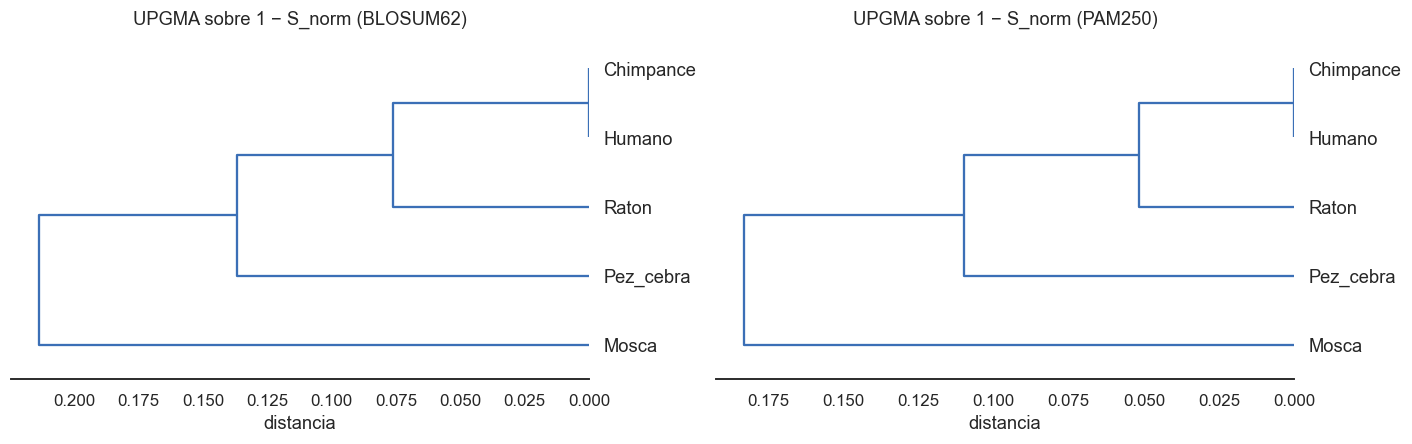

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, m in zip(axes, ["BLOSUM62", "PAM250"]):
    distancia = 1 - normalizadas[m]
    np.fill_diagonal(distancia.values, 0)
    Z = linkage(squareform(distancia.values, checks=False), method="average")
    dendrogram(Z, labels=especies, orientation="left", ax=ax, color_threshold=0,
               above_threshold_color="#3b6fb6")
    ax.set_title(f"UPGMA sobre 1 − S_norm ({m})")
    ax.set_xlabel("distancia")
    ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
fig.savefig(RESULTADOS / "dendrograma.png", bbox_inches="tight")
plt.show()

El árbol junta a humano y chimpancé (distancia 0), luego añade el ratón, después el pez y
por último la mosca. El orden de las ramas coincide con la filogenia real (primates →
mamíferos → vertebrados → bilaterales). Aun así, conviene no tomarlo como un árbol
filogenético:

- UPGMA supone un reloj molecular constante, y ya hemos visto que en los primates el
  citocromo c evolucionó más rápido.
- Un único gen de ~105 aa da muy pocas posiciones informativas (humano y chimpancé no se
  pueden distinguir).
- Una filogenia de verdad se construye con un alineamiento múltiple y un modelo de
  evolución (máxima verosimilitud o Neighbor-Joining sobre distancias corregidas), no con
  puntuaciones de alineamientos por pares.

## 8. Efecto de los huecos en los extremos *(aportación)*

Por defecto, `PairwiseAligner` penaliza igual los huecos de los extremos que los internos.
Pero la mosca tiene una extensión N-terminal que no existe en las demás especies, y no tiene
mucho sentido biológico castigarla con -10 como si fuera una deleción en mitad de la
proteína. Probamos a **no penalizar los huecos de los extremos** (`end_gap_score = 0`), como
hace la opción `-endweight` de `needle`:

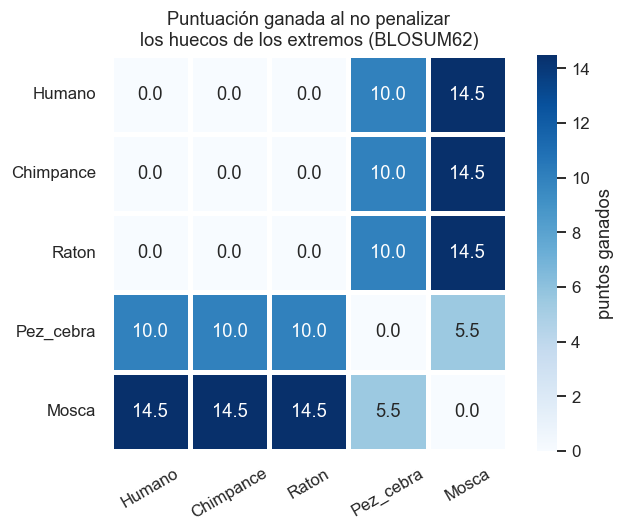

target            0 ----MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNK
                  0 ----.||||||||.|...|.||||||.|||||.|||||||.|||||||.|..||.|||.|
query             0 MGVPAGDVEKGKKLFVQRCAQCHTVEAGGKHKVGPNLHGLIGRKTGQAAGFAYTDANKAK

target           56 GIIWGEDTLMEYLENPKKYIPGTKMIFVGIKKKEERADLIAYLKKATNE 105
                 60 ||.|.||||.|||||||||||||||||.|.||..||.|||||||.||.- 109
query            60 GITWNEDTLFEYLENPKKYIPGTKMIFAGLKKPNERGDLIAYLKSATK- 108



In [11]:
alineador_libre = crear_alineador("BLOSUM62")
alineador_libre.end_gap_score = 0

scores_libre = matriz_puntuaciones(registros, alineador_libre)
diferencia = scores_libre - scores_b62

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(diferencia, annot=True, fmt=".1f", cmap="Blues", square=True,
            linewidths=2, linecolor="white", cbar_kws={"label": "puntos ganados"}, ax=ax)
ax.set_title("Puntuación ganada al no penalizar\nlos huecos de los extremos (BLOSUM62)")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

print(alineador_libre.align(humano.seq, mosca.seq)[0])

Solo cambian los pares en los que intervienen la mosca o el pez, que son las secuencias de
longitud distinta. Ahora el alineamiento humano–mosca deja la extensión N-terminal de la
mosca sin emparejar (`MGVP` frente a `----`), en lugar de partirla con un hueco interno
tras la primera M. Es una solución más razonable biológicamente. Los parámetros de los
huecos son tan importantes como la matriz.

## 9. Conclusiones

1. El bucle de todos contra todos con `PairwiseAligner` + BLOSUM62 da una matriz simétrica
   de 5 × 5 cuyas puntuaciones **bajan con la distancia evolutiva**: chimpancé > ratón >
   pez > mosca respecto al humano.
2. El citocromo c de **humano y chimpancé es idéntico**, y el de humano y mosca coincide
   en un ~74 % tras unos 600 millones de años. Los residuos que sujetan el hemo (CXXCH y
   Met80) se conservan en todas las especies.
3. Los datos muestran un efecto real: **el citocromo c evolucionó más rápido en los
   primates**, por eso el ratón está más cerca del pez y de la mosca que el humano.
4. **Las puntuaciones brutas no se pueden comparar** entre pares de longitud distinta ni
   entre matrices distintas. Hay que normalizarlas (o usar la identidad) antes de sacar
   conclusiones.
5. Cambiar la matriz de sustitución **no altera el orden de los pares** (Spearman ≈ 1),
   pero sí cuánto se separan. Las matrices estrictas (PAM30, BLOSUM80/90) separan más a las
   especies lejanas.

> **Advertencia.** Una puntuación de alineamiento depende de las decisiones que tomamos:
> la matriz, las penalizaciones de los huecos, cómo tratar los extremos y la proteína
> elegida. Con una sola proteína tan conservada como el citocromo c, el ranking de
> parecidos es fiable, pero conclusiones como «el ratón está más cerca de la mosca que el
> humano» hablan de **este gen**, no de las especies.